**Assignment 3. Real-Time Time Series Analysis and Anomaly Detection. Done by Ayazhan Sailauova, BDA-2402**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.api import Holt
from sklearn.ensemble import IsolationForest

In [2]:
dataset = {
    "Time": ["12:00", "12:05", "12:10", "12:15", "12:20", "12:25", "12:30", "12:35", "12:40", "12:45", "12:50", "12:55", "13:00", "13:05"],
    "Temperature_C": [-8.0, -8.2, -8.1, -8.3, -8.4, -8.2, -8.5, -8.4, -8.6, -8.5, -8.7, -8.6, -8.8, -8.7],
    "Wind_mps": [4.2, 4.5, 4.3, 4.4, 4.6, 4.1, 4.8, 4.7, 4.9, 5.0, 5.1, 5.0, 5.2, 5.1],
    "PM25_ug_m3": [28, 30, 31, 29, 32, 35, 38, 41, 44, 47, 95, 110, 118, 45],
    "Humidity_%": [62, 61, 60, 60, 59, 58, 58, 57, 57, 56, 55, 54, 54, 55]
}

In [3]:
df = pd.DataFrame(dataset)
df

,Time,Temperature_C,Wind_mps,PM25_ug_m3,Humidity_%
0,12:00,-8.0,4.2,28,62
1,12:05,-8.2,4.5,30,61
2,12:10,-8.1,4.3,31,60
3,12:15,-8.3,4.4,29,60
4,12:20,-8.4,4.6,32,59
5,12:25,-8.2,4.1,35,58
6,12:30,-8.5,4.8,38,58
7,12:35,-8.4,4.7,41,57
8,12:40,-8.6,4.9,44,57
9,12:45,-8.5,5.0,47,56


A synthesized dataset consists of 14 observations made on 5 features, such as: Time, Temperature in C, Wind in m/s, PM25_ug_m3 and Humidity percentage.

**Part A — Time-Series Exploration**

In [4]:
df["Datetime"] = pd.to_datetime("2026-10-20 " + df["Time"])
df.set_index("Datetime", inplace=True)
df.drop(columns=["Time"], inplace=True)
df

,Temperature_C,Wind_mps,PM25_ug_m3,Humidity_%
Datetime,,,,
2026-10-20 12:00:00,-8.0,4.2,28,62
2026-10-20 12:05:00,-8.2,4.5,30,61
2026-10-20 12:10:00,-8.1,4.3,31,60
2026-10-20 12:15:00,-8.3,4.4,29,60
2026-10-20 12:20:00,-8.4,4.6,32,59
2026-10-20 12:25:00,-8.2,4.1,35,58
2026-10-20 12:30:00,-8.5,4.8,38,58
2026-10-20 12:35:00,-8.4,4.7,41,57
2026-10-20 12:40:00,-8.6,4.9,44,57


The 'Time' column was converted into 'Datetime' index column.

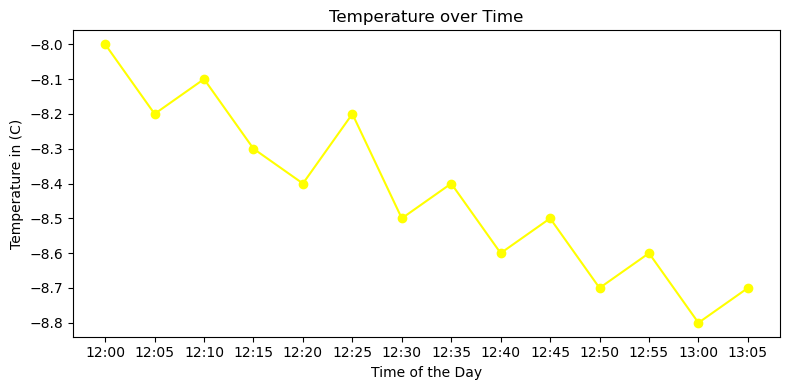

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(
    df.index.strftime("%H:%M"),
    df["Temperature_C"],
    color="yellow",
    marker="o"
)
plt.title("Temperature over Time")
plt.xlabel("Time of the Day")
plt.ylabel("Temperature in (C)")
plt.tight_layout()
plt.show()

There is a consistent downward trend in temperature measurements over the period. STarting from -8.0(C) at 12:00, the temperature decreases to a minimum of -8.8(C) at 13:00. No strong seasonality was identified, there are some fluctuations every 10 minutes. The changes of the temperature does not show any abrupt outliers.

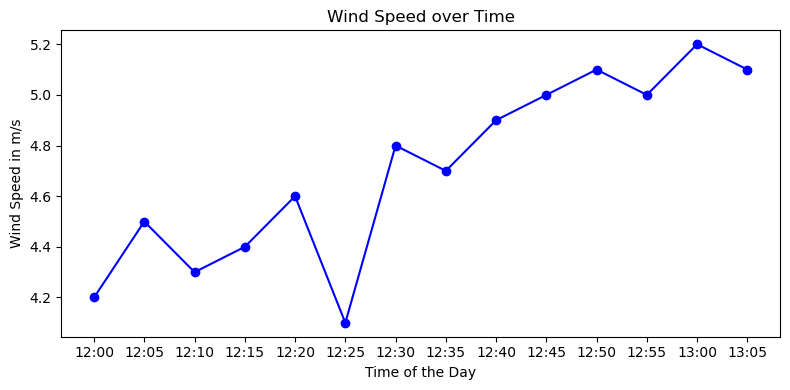

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(
    df.index.strftime("%H:%M"),
    df["Wind_mps"],
    color="blue",
    marker="o"
)
plt.title("Wind Speed over Time")
plt.xlabel("Time of the Day")
plt.ylabel("Wind Speed in m/s")
plt.tight_layout()
plt.show()

The Wind Speed variable shows an increase from 4.2 m/s at 12:00 to 5.1 m/s at 13:05 with a maximum value of 5.2 m/s at 13:00. There is no seasonality patterns. However, there is an abrupt decrease in wind speed to a value of 4.1 m/s at 12:25.

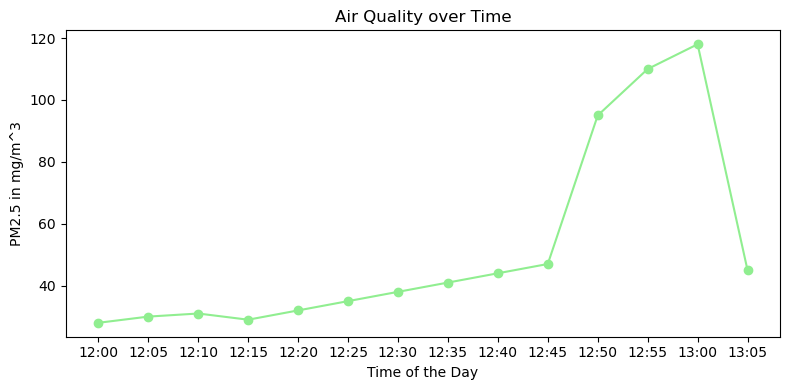

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(
    df.index.strftime("%H:%M"),
    df["PM25_ug_m3"],
    color="lightgreen",
    marker="o"
)
plt.title("Air Quality over Time")
plt.xlabel("Time of the Day")
plt.ylabel("PM2.5 in mg/m^3")
plt.tight_layout()
plt.show()

The air quality measures followed an upward trend over the 45-minute period, from 28 mg/m^3 at 12:00 to 47 mg/m^3 at 12:45. After 12:45, there was a spike of 118 mg/m^3 followed by a significant decrease to 45 mg/m^3. There is no seasonality pattern. Both a spike of air quality at 13:00 and a sudden drop at 13:05 represent an abrupt change of the values. Those valuesare considered as anomalies.

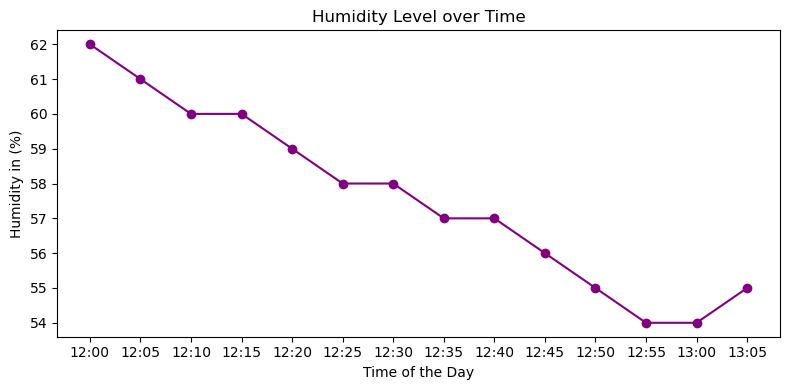

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(
    df.index.strftime("%H:%M"),
    df["Humidity_%"],
    color="purple",
    marker="o"
)
plt.title("Humidity Level over Time")
plt.xlabel("Time of the Day")
plt.ylabel("Humidity in (%)")
plt.tight_layout()
plt.show()

There is a strong downward trend of the humidity percentage over the period. The values are decreasing from 62% at 12:00 to 55% at 13:05, with a minimum pereancate of 54. A seasonality trend was not observed. Additionally, no abrupt changes were identified.

Overall, a likely anomaly interval will be considered from 12:50 to 13:00. During this time interval, the air quality indicator shows abrupt spikes and drops, whereas the humidity percentage along with temperature in (C) show the lowest values, and wind speed reaches the maximum value.

**Part B — Moving Average and Exponential Smoothing**

In [9]:
df["3-point MA"] = df["PM25_ug_m3"].rolling(window=3).mean()

df.index.freq = "5min"
model = Holt(df["PM25_ug_m3"], initialization_method="estimated")
fit_model = model.fit(
    smoothing_level=0.3, smoothing_trend=0.1, optimized=False
)
df["Smoothed value"] = fit_model.fittedvalues

df["Difference"] = df["3-point MA"] - df["Smoothed value"]

In [10]:
table = df.loc["2026-10-20 12:10:00":"2026-10-20 13:00:00"].copy()

table["3-point MA"] = table["3-point MA"].round(2)
table["Smoothed value"] = table["Smoothed value"].round(2)
table["Difference"] = table["Difference"].round(2)

print(
    table[
        ["PM25_ug_m3", "3-point MA", "Smoothed value", "Difference"]
    ].to_string()
)

                     PM25_ug_m3  3-point MA  Smoothed value  Difference
Datetime                                                               
2026-10-20 12:10:00          31       29.67           31.35       -1.68
2026-10-20 12:15:00          29       30.00           33.45       -3.45
2026-10-20 12:20:00          32       30.67           34.18       -3.51
2026-10-20 12:25:00          35       32.00           35.53       -3.53
2026-10-20 12:30:00          38       35.00           37.36       -2.36
2026-10-20 12:35:00          41       38.00           39.56       -1.56
2026-10-20 12:40:00          44       41.00           42.04       -1.04
2026-10-20 12:45:00          47       44.00           44.74       -0.74
2026-10-20 12:50:00          95       62.00           47.59       14.41
2026-10-20 12:55:00         110       84.00           65.41       18.59
2026-10-20 13:00:00         118      107.67           83.73       23.94


The table demonstrates how exponential smoothing with an alpha of 0.3 differs compared to the 3-point moving average. This shows that double exponential smoothing gives an importance to recent observations by introducing a trend component. The  sharp increase in the residual difference from -0.74 at 12:45 to 14.41 at 12:50 isolates the air pollution anomaly.  

**Part C — Statistical Anomaly Detection**

In [11]:
df["Rolling mean"] = df["PM25_ug_m3"].rolling(window=3).mean()
df["Rolling std"] = df["PM25_ug_m3"].rolling(window=3).std()
df["Threshold"] = 2 * df["Rolling std"]
df["Anomaly"] = ((df["PM25_ug_m3"] - df["Rolling mean"]).abs() > df["Threshold"])

In [12]:
anomaly_table = df.loc["2026-10-20 12:35:00":"2026-10-20 13:00:00"].copy()
anomaly_table = anomaly_table.rename(columns={"PM25_ug_m3": "Observed PM2.5"})

anomaly_table["Rolling mean"] = anomaly_table["Rolling mean"].round(2)
anomaly_table["Rolling std"] = anomaly_table["Rolling std"].round(2)
anomaly_table["Threshold"] = anomaly_table["Threshold"].round(2)

print(
    anomaly_table[
        ["Observed PM2.5", "Rolling mean", "Rolling std", "Threshold", "Anomaly"]
    ].to_string()
)

                     Observed PM2.5  Rolling mean  Rolling std  Threshold  Anomaly
Datetime                                                                          
2026-10-20 12:35:00              41         38.00         3.00       6.00    False
2026-10-20 12:40:00              44         41.00         3.00       6.00    False
2026-10-20 12:45:00              47         44.00         3.00       6.00    False
2026-10-20 12:50:00              95         62.00        28.62      57.24    False
2026-10-20 12:55:00             110         84.00        32.91      65.82    False
2026-10-20 13:00:00             118        107.67        11.68      23.35    False


An anomaly detection pipeline uses a 3-observation rolling window to compute the moving mean and moving standard deviation of the air quality observations. The threshold for the detection equals to twice rolling standard deviation. No anomalies were detected.

**Part D — Compare Detection Methods**

In [13]:
X = df[["PM25_ug_m3"]].values
iso = IsolationForest(contamination=0.2, random_state=42)
df["anomaly predictions"] = iso.fit_predict(X)
df["detected points"] = df["anomaly predictions"] == -1

In [14]:
comparison_table = df.loc["2026-10-20 12:35:00":"2026-10-20 13:00:00"].copy()

comparison_table = comparison_table[["PM25_ug_m3", "Anomaly", "detected points"]].rename(
    columns={
        "PM25_ug_m3": "Observed PM2.5",
        "Anomaly": "Rolling Threshold Anomaly",
        "detected points": "Isolation Forest Anomaly",
    }
)

print(comparison_table.to_string())

                     Observed PM2.5  Rolling Threshold Anomaly  Isolation Forest Anomaly
Datetime                                                                                
2026-10-20 12:35:00              41                      False                     False
2026-10-20 12:40:00              44                      False                     False
2026-10-20 12:45:00              47                      False                     False
2026-10-20 12:50:00              95                      False                      True
2026-10-20 12:55:00             110                      False                      True
2026-10-20 13:00:00             118                      False                      True


The rolling threshold method is more interpretable because of its statistical parameters background, whereas Isolation Forest is a non-parametric tree-based model. However, the Isolation Forest detects abrupt spikes more quickly because including the outlier inside a rolling window expands the standard deviation and fails to mark the anomaly. Isolation Forest is suitable for detecting non-linear spikes during the real-time streaming because it identifies observations that are easier to isolate from the rest of the data.


**Part E — Forecast/Operational Recommendation**

In [16]:
holt_model = Holt(df["PM25_ug_m3"]).fit()
forecast_values = holt_model.forecast(steps=10)

forecast_index = pd.date_range(
    "2026-10-20 13:10:00", periods=10, freq="5min"
)
forecast_df = pd.DataFrame(
    {"Forecasted PM2.5": forecast_values.round(2)}, index=forecast_index
)
forecast_df.index.name = "Datetime"

statuses = []
actions = []

for val in forecast_df["Forecasted PM2.5"]:
    if val > 55.5:
        statuses.append("Red")
        actions.append("Start ventilation")
    elif val > 35.5:
        statuses.append("Yellow")
        actions.append("Send Alert")
    else:
        statuses.append("Green")
        actions.append("Normal Monitoring")

forecast_df["Status"] = statuses
forecast_df["Action"] = actions

print(forecast_df.to_string())

                     Forecasted PM2.5  Status             Action
Datetime                                                        
2026-10-20 13:10:00              47.0  Yellow         Send Alert
2026-10-20 13:15:00              49.0  Yellow         Send Alert
2026-10-20 13:20:00              51.0  Yellow         Send Alert
2026-10-20 13:25:00              53.0  Yellow         Send Alert
2026-10-20 13:30:00              55.0  Yellow         Send Alert
2026-10-20 13:35:00              57.0     Red  Start ventilation
2026-10-20 13:40:00              59.0     Red  Start ventilation
2026-10-20 13:45:00              61.0     Red  Start ventilation
2026-10-20 13:50:00              63.0     Red  Start ventilation
2026-10-20 13:55:00              65.0     Red  Start ventilation


The Holt's Exponential Smooting was used to forecast next 10 PM2.5 records. The dashboard should display the observed records along with its status and supporting action. Yellow Status shows an increase of pollution (value > 35.5mg/m^3) and "Sends Alert" to facility operators. Red status is a threshold that displays when value exceeds 55.5mg/m^3 and sets the action to "Start ventilation". The alert should be send via the most common messanger to the facility technicians.